# Ideal Rankine Cycle - Heat Efficiency, η (理想ランキンサイクルの熱効率)

The **Rankine cycle** is the idealized thermodynamic cycle used by most steam power plants. It has 4 processes:

| State | Process | Description |
|---|---|---|
| 1 → 2 | Isentropic compression | Pump raises saturated liquid from condenser pressure $p_1$ to boiler pressure $p_2$ |
| 2 → 3 | Constant-pressure heat addition | Boiler heats/vaporizes/superheats water to $T_3$ at $p_2$ |
| 3 → 4 | Isentropic expansion | Turbine expands steam back down to $p_1$, producing work |
| 4 → 1 | Constant-pressure heat rejection | Condenser rejects heat, returning saturated liquid at $p_1$ |

$$\eta_{th} = \frac{w_{net}}{q_{in}} = \frac{(h_3-h_4)-(h_2-h_1)}{h_3-h_2}$$

Steam properties (enthalpy $h$, entropy $s$) are obtained from [PYroMat](https://pyromat.org/), which uses the IAPWS-95 water equation of state - the same reference used to build steam tables.

Reference: [Wikipedia - Rankine cycle](https://en.wikipedia.org/wiki/Rankine_cycle)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyromat as pm

pm.config['unit_pressure'] = 'MPa'   # SI-derived pressure unit throughout (PYroMat defaults to bar)
water = pm.get('mp.H2O')             # remaining PYroMat unit defaults: K, kJ/kg, kJ/kg-K

class RankineCycle:
    # Ideal (no losses) Rankine cycle: isentropic pump & turbine, saturated states at condenser/boiler exits.

    def __init__(self, p_boiler, T_boiler, p_condenser):
        # INPUT INITIAL INFORMATION
        #   p_boiler    : boiler pressure [MPa]
        #   T_boiler    : turbine-inlet (boiler exit) temperature [K]
        #   p_condenser : condenser pressure [MPa]
        self.p2 = p_boiler
        self.T3 = T_boiler
        self.p1 = p_condenser
        self._solve()

    def _solve(self):
        # state 1 : saturated liquid leaving the condenser
        hf1, hg1 = water.hs(p=self.p1)
        sf1, sg1 = water.ss(p=self.p1)
        vf1, vg1 = water.vs(p=self.p1)
        self.h1, self.s1, self.v1 = hf1[0], sf1[0], vf1[0]
        self.hf1, self.hg1, self.sf1, self.sg1 = hf1[0], hg1[0], sf1[0], sg1[0]

        # state 2 : pump exit (isentropic, incompressible liquid -> w_pump = v*Δp)
        self.w_pump = self.v1*(self.p2-self.p1)*1000   # MPa*m3/kg -> kJ/kg (1 MPa*m3 = 1000 kJ)
        self.h2 = self.h1 + self.w_pump

        # state 3 : boiler exit / turbine inlet
        self.h3 = water.h(T=self.T3, p=self.p2).item()
        self.s3 = water.s(T=self.T3, p=self.p2).item()

        # state 4 : turbine exit (isentropic expansion to condenser pressure)
        T4, x4 = water.T_s(s=self.s3, p=self.p1, quality=True)
        self.T4, self.x4 = T4[0], x4[0]
        if self.x4 >= 0:  # wet steam
            self.h4 = self.hf1 + self.x4*(self.hg1-self.hf1)
        else:              # still superheated
            self.h4 = water.h(T=self.T4, p=self.p1).item()

        # energy balance
        self.q_in = self.h3-self.h2
        self.q_out = self.h4-self.h1
        self.w_turbine = self.h3-self.h4
        self.w_net = self.w_turbine - self.w_pump
        self.eta = self.w_net/self.q_in

    def summary(self):
        print(f"State 1 (pump inlet)     : h1={self.h1:8.2f} kJ/kg, s1={self.s1:.4f} kJ/kg-K")
        print(f"State 2 (boiler inlet)   : h2={self.h2:8.2f} kJ/kg  (w_pump={self.w_pump:.2f} kJ/kg)")
        print(f"State 3 (turbine inlet)  : h3={self.h3:8.2f} kJ/kg, s3={self.s3:.4f} kJ/kg-K")
        print(f"State 4 (turbine exit)   : h4={self.h4:8.2f} kJ/kg  (quality x4={self.x4:.4f})")
        print()
        print(f"q_in      = {self.q_in:8.2f} kJ/kg")
        print(f"q_out     = {self.q_out:8.2f} kJ/kg")
        print(f"w_turbine = {self.w_turbine:8.2f} kJ/kg")
        print(f"w_pump    = {self.w_pump:8.2f} kJ/kg")
        print(f"w_net     = {self.w_net:8.2f} kJ/kg")
        print(f"eta_th    = {self.eta*100:.2f} %")

### Sample: classic textbook case
Boiler at 3 MPa superheated to 350°C, condenser at 75 kPa (0.075 MPa) - this is a widely used worked example (Cengel & Boles, *Thermodynamics: An Engineering Approach*), giving η_th ≈ 26.0% and x4 ≈ 0.886, which matches the calculation below and confirms the implementation.

In [2]:
cycle = RankineCycle(p_boiler=3, T_boiler=350+273.15, p_condenser=0.075)
cycle.summary()

State 1 (pump inlet)     : h1=  384.43 kJ/kg, s1=1.2132 kJ/kg-K
State 2 (boiler inlet)   : h2=  387.47 kJ/kg  (w_pump=3.03 kJ/kg)
State 3 (turbine inlet)  : h3= 3116.10 kJ/kg, s3=6.7450 kJ/kg-K
State 4 (turbine exit)   : h4= 2403.03 kJ/kg  (quality x4=0.8861)

q_in      =  2728.63 kJ/kg
q_out     =  2018.60 kJ/kg
w_turbine =   713.07 kJ/kg
w_pump    =     3.03 kJ/kg
w_net     =   710.03 kJ/kg
eta_th    = 26.02 %


In [3]:
from rich.console import Console
from rich.table import Table

console = Console()

states = Table(title="Rankine cycle state points")
states.add_column("State"); states.add_column("h [kJ/kg]", justify="right"); states.add_column("Note")
states.add_row("1 (pump inlet)",    f"{cycle.h1:.2f}", "sat. liquid @ condenser p")
states.add_row("2 (boiler inlet)",  f"{cycle.h2:.2f}", f"w_pump = {cycle.w_pump:.2f} kJ/kg")
states.add_row("3 (turbine inlet)", f"{cycle.h3:.2f}", "boiler exit")
states.add_row("4 (turbine exit)",  f"{cycle.h4:.2f}", f"quality x4 = {cycle.x4:.3f}")
console.print(states)

results = Table(title="Cycle performance")
results.add_column("Quantity"); results.add_column("Value", justify="right")
for name, val, unit in [("q_in", cycle.q_in, "kJ/kg"), ("q_out", cycle.q_out, "kJ/kg"),
                         ("w_turbine", cycle.w_turbine, "kJ/kg"), ("w_pump", cycle.w_pump, "kJ/kg"),
                         ("w_net", cycle.w_net, "kJ/kg")]:
    results.add_row(name, f"{val:.2f} {unit}")
results.add_row("eta_th", f"{cycle.eta*100:.2f} %", style="bold green")
console.print(results)

                Rankine cycle state points                 
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ State             ┃       h ┃ Note                      ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 1 (pump inlet)    │  384.43 │ sat. liquid @ condenser p │
│ 2 (boiler inlet)  │  387.47 │ w_pump = 3.03 kJ/kg       │
│ 3 (turbine inlet) │ 3116.10 │ boiler exit               │
│ 4 (turbine exit)  │ 2403.03 │ quality x4 = 0.886        │
└───────────────────┴─────────┴───────────────────────────┘

      Cycle performance      
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Quantity  ┃         Value ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ q_in      │ 2728.63 kJ/kg │
│ q_out     │ 2018.60 kJ/kg │
│ w_turbine │  713.07 kJ/kg │
│ w_pump    │    3.03 kJ/kg │
│ w_net     │  710.03 kJ/kg │
│ eta_th    │       26.02 % │
└───────────┴───────────────┘

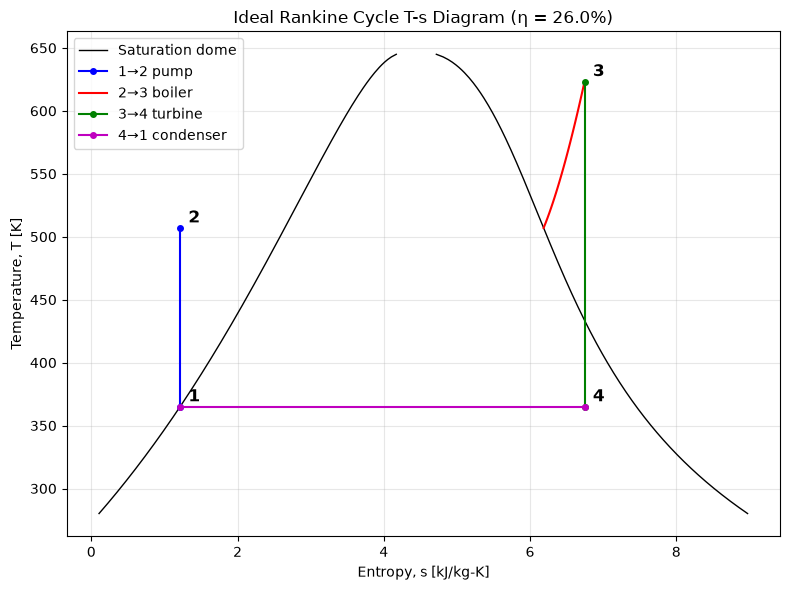

In [4]:
# T-s diagram with saturation dome
p_dome = np.geomspace(0.001, 21.5, 400)   # MPa, up to near-critical pressure (stay clear of 22.064 MPa critical point)
Tsat = water.Ts(p=p_dome)
sf_dome, sg_dome = water.ss(p=p_dome)

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(sf_dome, Tsat, 'k-', lw=1)
ax.plot(sg_dome, Tsat, 'k-', lw=1, label='Saturation dome')

s_pts = [cycle.s1, cycle.s1, cycle.s3, cycle.s3]      # 1->2 isentropic (s const)
T_pts = [ (water.Ts(p=cycle.p1))[0], (water.Ts(p=cycle.p2))[0], cycle.T3, cycle.T4]
# more accurate 2->3 path at constant p2 (compressed liquid -> superheated vapor)
T23 = np.linspace(water.Ts(p=cycle.p2)[0], cycle.T3, 30)
s23 = water.s(T=T23, p=cycle.p2)

ax.plot([cycle.s1, cycle.s1], [water.Ts(p=cycle.p1)[0], water.Ts(p=cycle.p2)[0]], 'b-o', ms=4, label='1→2 pump')
ax.plot(s23, T23, 'r-', label='2→3 boiler')
ax.plot([cycle.s3, cycle.s3], [cycle.T3, cycle.T4], 'g-o', ms=4, label='3→4 turbine')
ax.plot([cycle.s3, cycle.s1], [cycle.T4, water.Ts(p=cycle.p1)[0]], 'm-o', ms=4, label='4→1 condenser')

for lbl, s, T in zip(['1','2','3','4'], [cycle.s1, cycle.s1, cycle.s3, cycle.s3],
                      [water.Ts(p=cycle.p1)[0], water.Ts(p=cycle.p2)[0], cycle.T3, cycle.T4]):
    ax.annotate(lbl, (s,T), textcoords="offset points", xytext=(6,4), fontsize=12, fontweight='bold')

ax.set_xlabel('Entropy, s [kJ/kg-K]')
ax.set_ylabel('Temperature, T [K]')
ax.set_title(f'Ideal Rankine Cycle T-s Diagram (η = {cycle.eta*100:.1f}%)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Effect of boiler pressure on efficiency
Raising boiler pressure (holding turbine-inlet temperature and condenser pressure fixed) raises the average temperature of heat addition, which raises $\eta_{th}$ - a standard Rankine-cycle result.

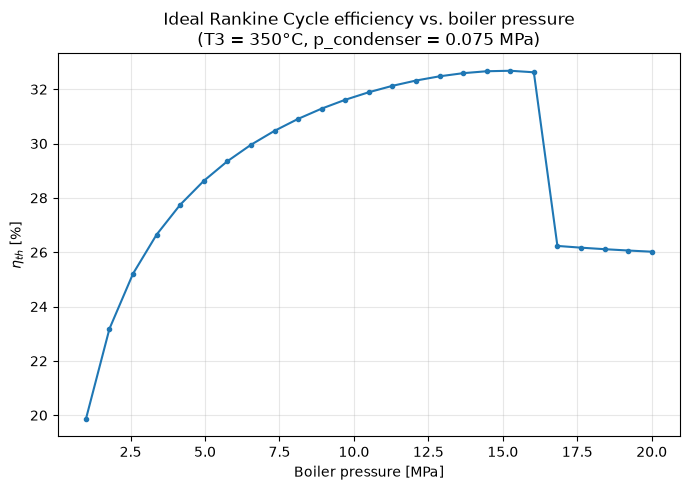

In [5]:
p_boiler_range = np.linspace(1, 20, 25)
etas = []
for p2 in p_boiler_range:
    c = RankineCycle(p_boiler=p2, T_boiler=350+273.15, p_condenser=0.075)
    etas.append(c.eta*100)

plt.figure(figsize=(7,5))
plt.plot(p_boiler_range, etas, marker='.')
plt.xlabel('Boiler pressure [MPa]')
plt.ylabel(r'$\eta_{th}$ [%]')
plt.title('Ideal Rankine Cycle efficiency vs. boiler pressure\n(T3 = 350°C, p_condenser = 0.075 MPa)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reference :
1. [Wikipedia - Rankine cycle](https://en.wikipedia.org/wiki/Rankine_cycle)
2. [PYroMat documentation](https://pyromat.org/)